In [1]:
# Install catalax
# !pip install catalax

In [2]:
import warnings

import catalax as ctx

warnings.filterwarnings("ignore")

# Parameter Optimization with Catalax

This notebook demonstrates how to perform parameter optimization using Catalax. We'll use a Michaelis-Menten kinetics model as an example and fit its parameters to experimental data.

## Overview

The notebook covers:
1. Setting up a Michaelis-Menten kinetic model
2. Loading experimental data from a Croissant dataset
3. Configuring parameters for optimization
4. Running parameter inference using LMFit
5. Analyzing the optimization results
6. Weighted least squares with a noise model

The Michaelis-Menten model describes enzyme kinetics with the equation:


In [3]:
# Initialize the model
model = ctx.Model(name="Michaelis-Menten")

# Add species
model.add_state("s1")

# Add ODEs
model.add_ode("s1", "- (v_max * s1) / ( K_m + s1)")

# Prepare the model for bayes and define priors
model.parameters["v_max"].value = 7.0
model.parameters["K_m"].value = 100.0

model

,name,symbol,type
0,s1,s1,None


,name,symbol,value,constant,initial_value,equation,lower_bound,upper_bound,hdi
0,K_m,K_m,100.0,False,None,None,None,None,None
1,v_max,v_max,7.0,False,None,None,None,None,None


""


""


""



Model(
    name='Michaelis-Menten',
    odes=DottedDict({'s1': ODE(equation=-s1*v_max/(K_m + s1), parameters=DottedDict({'K_m': Parameter(name='K_m', symbol=K_m, value=100.0, constant=False, identifiability=None, initial_value=None, equation=None, lower_bound=None, upper_bound=None, hdi=None, prior=None), 'v_max': Parameter(name='v_max', symbol=v_max, value=7.0, constant=False, identifiability=None, initial_value=None, equation=None, lower_bound=None, upper_bound=None, hdi=None, prior=None)}), state=State(name='s1', symbol=s1, type=None), observable=True)}),
    states=,
    parameters=,
    reactions=,
    constants=,
    assignments=
)

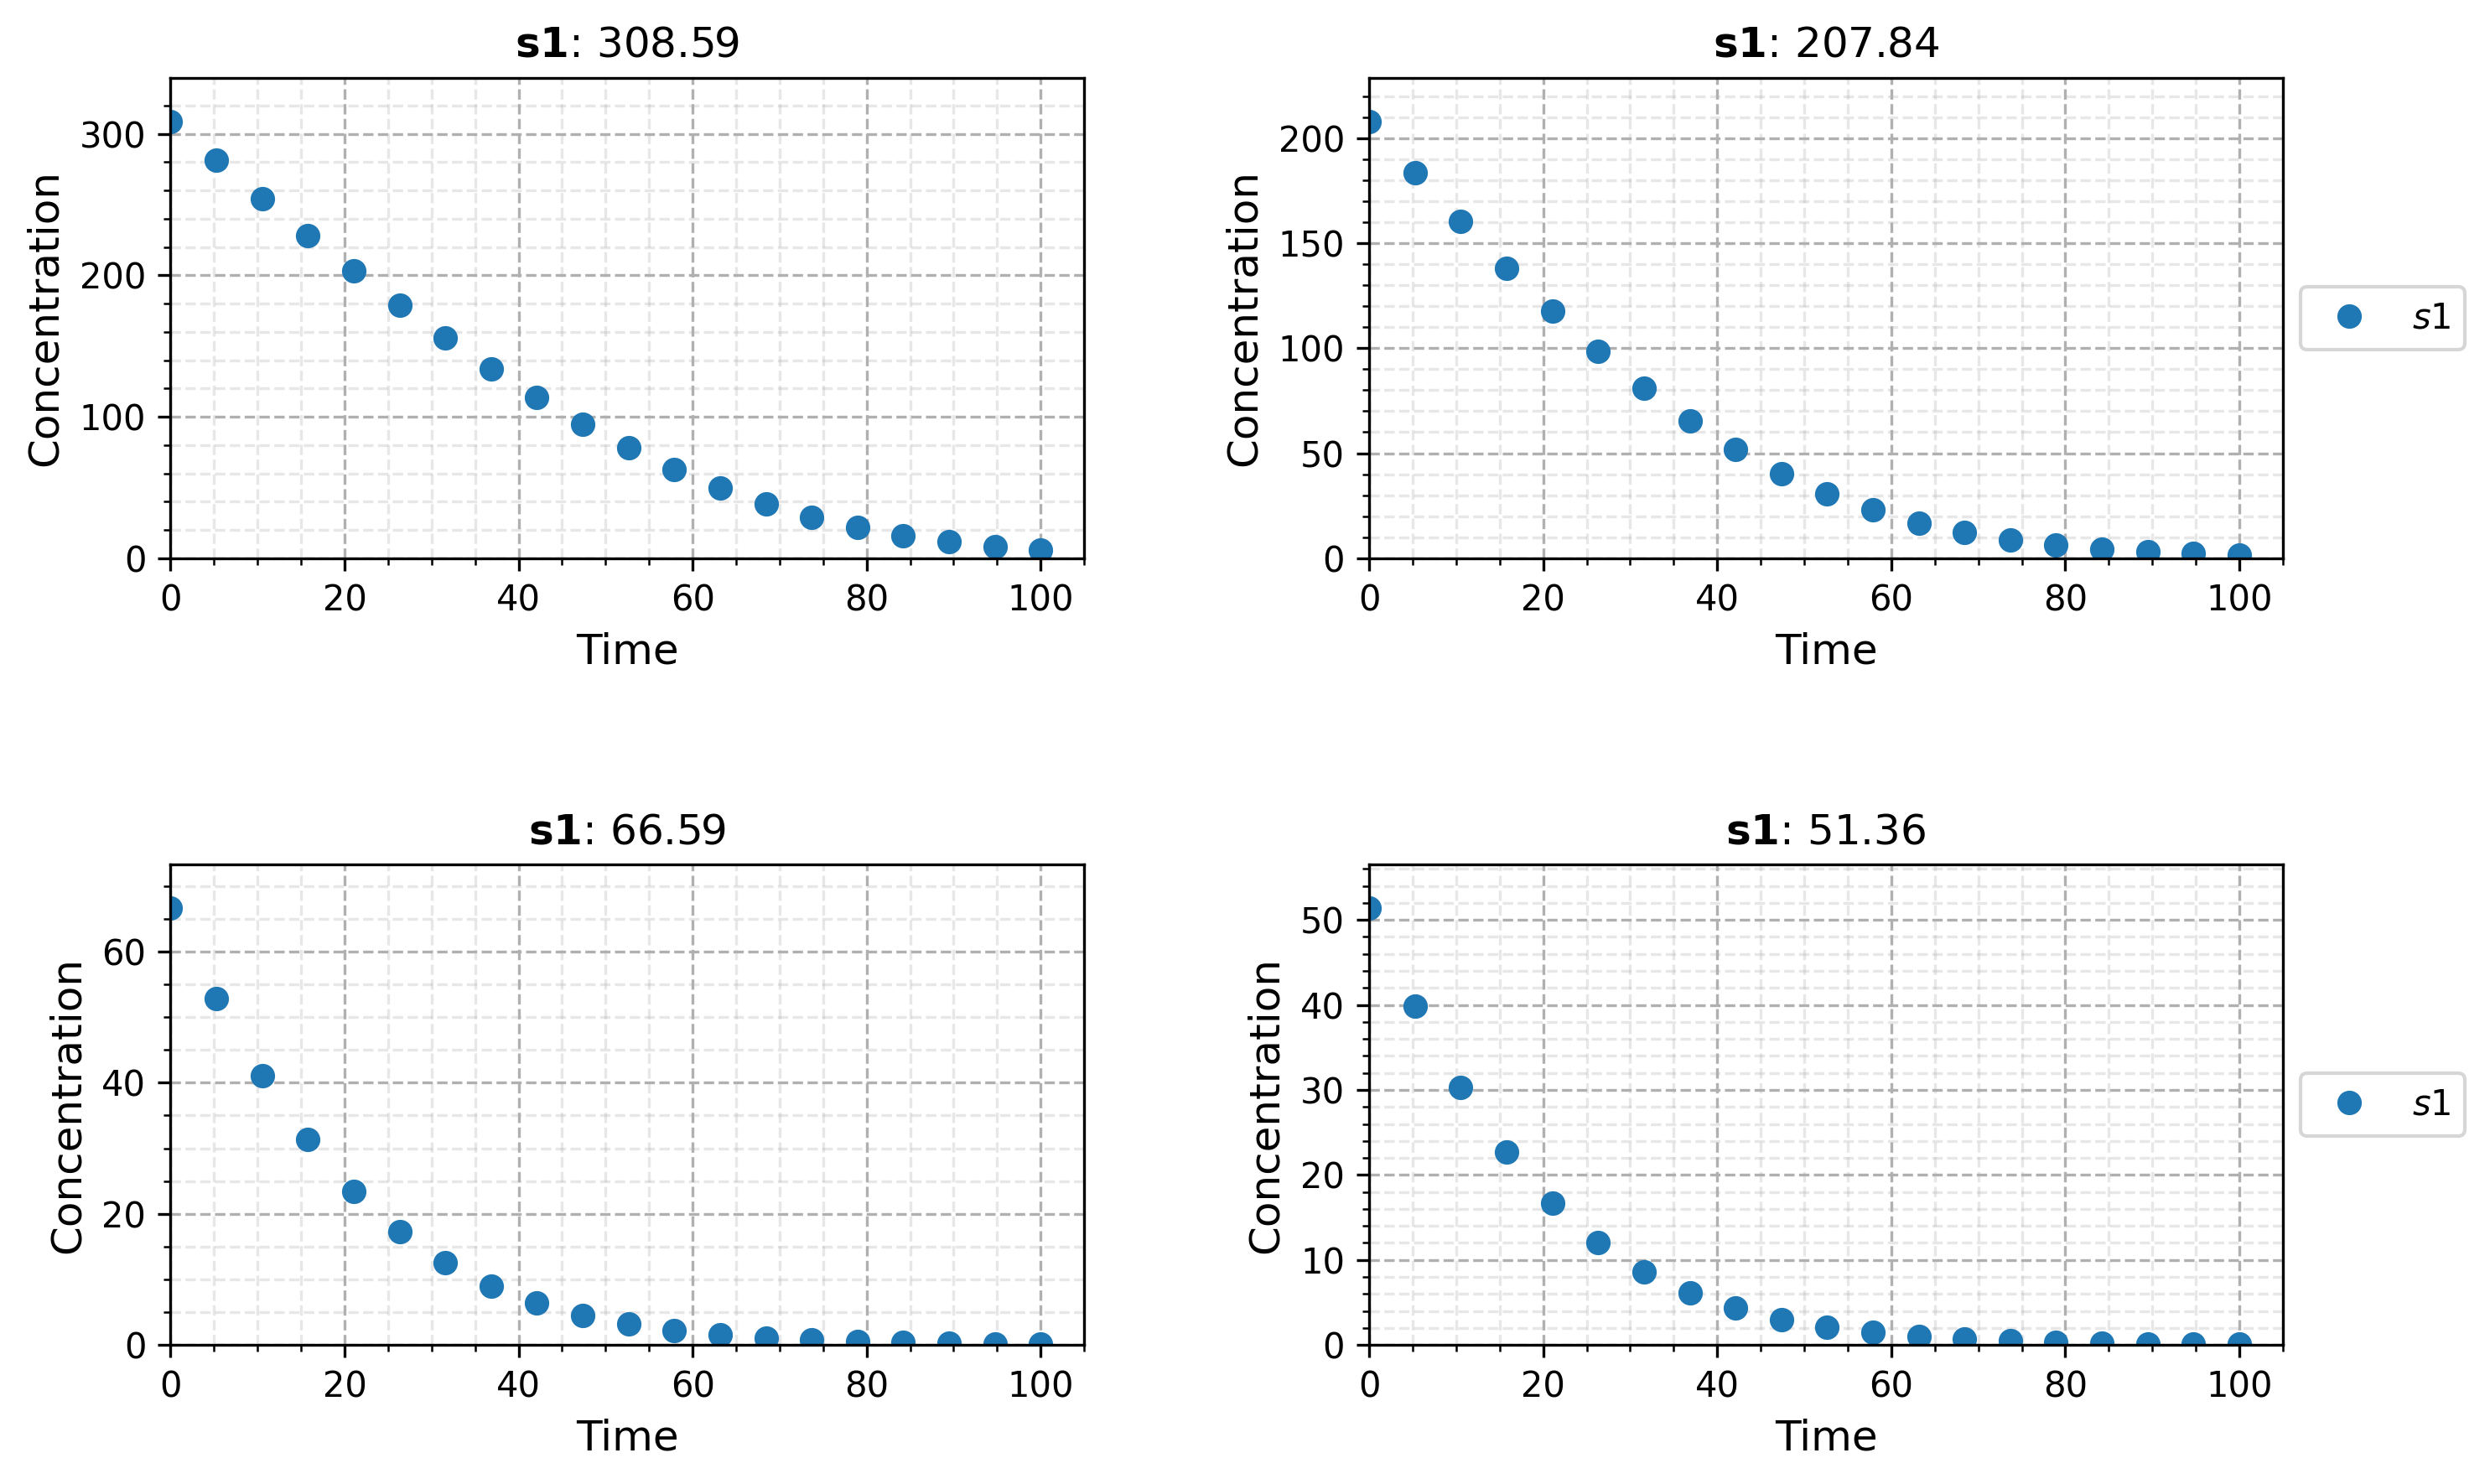

In [4]:
dataset = ctx.Dataset.from_croissant("./datasets/croissant_dataset.zip")
f = dataset.plot(measurement_ids=[m.id for m in dataset.measurements[0:4]])

In [5]:
# In order to perform optimization, we need to add initial values.
model.parameters["v_max"].initial_value = 10.0
model.parameters["K_m"].initial_value = 120.0

# ... and to make sure to be as realistic as possible.
model.parameters["v_max"].value = None
model.parameters["K_m"].value = None

In [6]:
# Perform the optimization (least squares on the observable states)
result, new_model = ctx.optimize(
    model=model,
    dataset=dataset,
    global_upper_bound=1e5,
    global_lower_bound=1e-6,
)

<lmfit.minimizer.MinimizerResult object at 0x134376660>

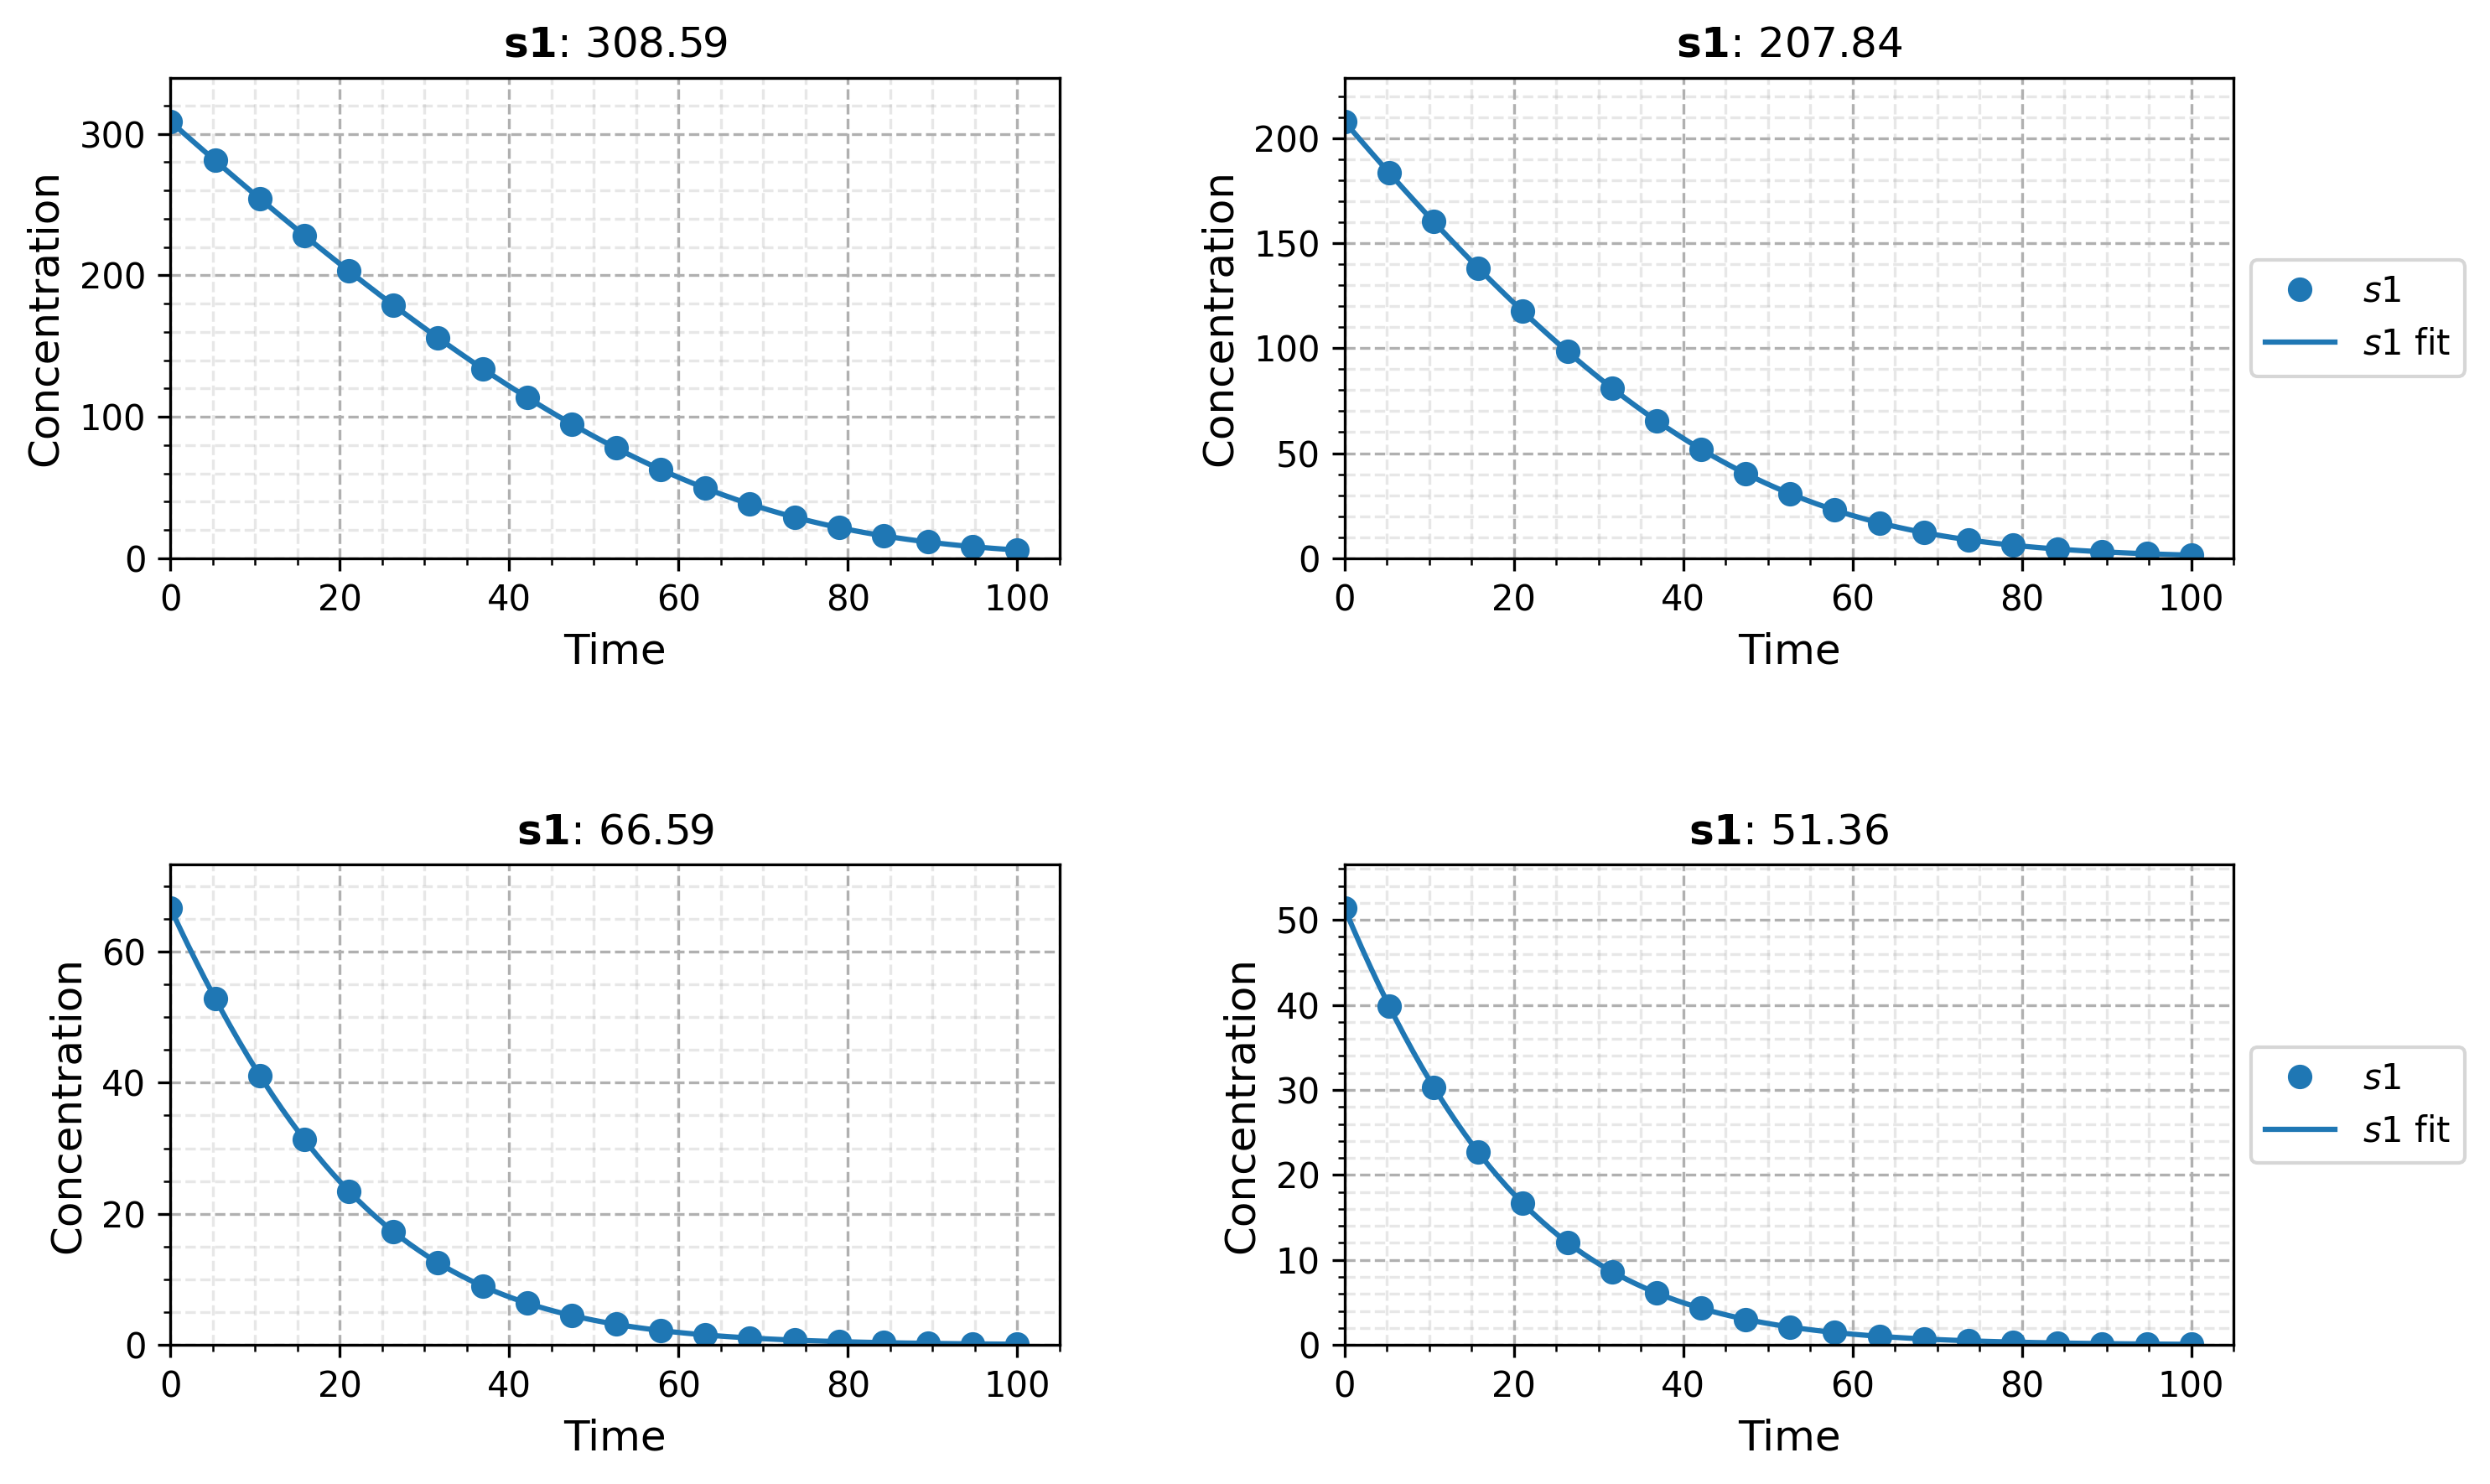

In [7]:
f = dataset.plot(
    predictor=new_model,
    measurement_ids=[m.id for m in dataset.measurements[0:4]],
)

## Weighted least squares

Measured data are noisy, and the noise of an assay often grows with the measured amount. To see this, we add 5 % proportional noise to the data, $y \cdot (1 + \mathcal{N}(0, 0.05))$.

If the noise is known, pass it as `noise=`: a noise model from `ctx.noise` or the standard deviations themselves. `Proportional(cv, floor)` has the standard deviation $\sqrt{\text{floor}^2 + (\text{cv} \cdot y)^2}$; here `cv` is the 5 % we added and `floor` a small value that keeps the standard deviation positive near zero. The residuals are divided by these standard deviations, evaluated once on the measured data. They are taken as absolute, so the standard errors are not rescaled; the reduced chi-square `result.redchi` is close to 1 when the noise model describes the residuals.


In [8]:
noisy = dataset.augment(
    n_augmentations=1,
    seed=0,
    sigma=5e-2,
    append=False,
    multiplicative=True,
)

weighted, weighted_model = ctx.optimize(
    model=model,
    dataset=noisy,
    noise=ctx.noise.Proportional(cv=0.05, floor=0.01),
)

print(f"reduced chi-square: {weighted.redchi:.2f}")
for name, parameter in weighted.params.items():
    print(f"{name:6s} {parameter.value:8.3f} ± {parameter.stderr:.3f}")

<lmfit.minimizer.MinimizerResult object at 0x136f15310>

reduced chi-square: 0.94
K_m     100.288 ± 0.193
v_max     7.024 ± 0.010
